<a href="https://colab.research.google.com/github/mcellpurba/Kompleksitas-dan-Rancangan-Resume-Medis-Tidak-Terstruktur/blob/main/Kompleksitas_dan_Rancangan_Resume_Medis_Tidak_Terstruktur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Instalasi Library

In [1]:
!pip install -q pydantic google-genai pandas

Kode Utama Pipeline Ekstraksi Biomedik

In [2]:
import re
import json
import pandas as pd
from typing import List, Literal, Optional
from pydantic import BaseModel, Field

# =====================================================================
# BAGIAN 1: DEFINISI SKEMA DATA TERSTRUKTUR (STANDAR VALIDASI PYDANTIC)
# Mencegah AI Hallucination dengan memaksa output mengikuti struktur ketat
# =====================================================================

class RiwayatMedis(BaseModel):
    kondisi: str = Field(description="Nama penyakit atau kondisi medis")
    status: Literal["CONFIRMED", "NEGATED", "FAMILY_HISTORY"] = Field(
        description="Status apakah penyakit diderita (CONFIRMED), disangkal (NEGATED), atau riwayat keluarga"
    )
    durasi: Optional[str] = Field(None, description="Lama penyakit diderita jika ada")

class DiagnosisKlinis(BaseModel):
    nama_diagnosis: str
    estimasi_icd10: str = Field(description="Kode ICD-10 yang paling mendekati")
    tipe: Literal["PRIMER", "SEKUNDER"]

class ObatTerapi(BaseModel):
    nama_obat: str
    dosis: str
    rute_pemberian: str = Field(description="Contoh: Per Oral, Sublingual, IV, Injeksi")

class ResumeMedisTerstruktur(BaseModel):
    id_pasien_anonim: str
    keluhan_utama: str
    tanda_vital: dict
    riwayat_penyakit: List[RiwayatMedis]
    diagnosis: List[DiagnosisKlinis]
    terapi_obat: List[ObatTerapi]


# =====================================================================
# BAGIAN 2: TAHAP PREPROCESSING (DE-IDENTIFIKASI & NORMALISASI SINGKATAN)
# Mengatasi masalah privasi data (UU PDP) dan singkatan dokter yang ambigu
# =====================================================================

def deidentifikasi_data_pasien(teks: str) -> str:
    """Menyensor NIK, Nomor Rekam Medis, Telepon, dan Nama Pasien menggunakan Regex"""
    # Sensor NIK (16 digit angka)
    teks = re.sub(r'\b\d{16}\b', '[NIK_REDACTED]', teks)
    # Sensor No. RM (Format umum misal RM-123456 atau 6-8 digit)
    teks = re.sub(r'(?i)(no\.?\s*rm|rm)\s*[:\-]?\s*\d+', 'No.RM: [RM_REDACTED]', teks)
    # Sensor Nomor Telepon Indonesia
    teks = re.sub(r'\b(08|\+628)\d{8,11}\b', '[PHONE_REDACTED]', teks)
    # Sensor Nama Pasien setelah sapaan medis (Tn., Ny., An., Sdr.)
    teks = re.sub(r'\b(Tn|Ny|An|Sdr|Bp|Ibu)\.\s+[A-Z][a-z]+(\s+[A-Z][a-z]+)?', r'\1. [NAMA_REDACTED]', teks)
    return teks

def normalisasi_singkatan_medis(teks: str) -> str:
    """Membakukan singkatan lokal dokter Indonesia sebelum masuk ke mesin NLP/LLM"""
    kamus_medis = {
        r'\bsmrs\b': 'sebelum masuk rumah sakit',
        r'\briw\.?\b': 'riwayat',
        r'\bdm\b': 'Diabetes Mellitus',
        r'\bht\b': 'Hipertensi',
        r'\btd\b': 'Tekanan Darah',
        r'\bhr\b': 'Heart Rate (Nadi)',
        r'\brr\b': 'Respiratory Rate (Napas)',
        r'\bdx\b': 'Diagnosis',
        r'\btx\b': 'Terapi Obat',
        r'\bpo\b': 'per oral (minum)',
        r'\biv\b': 'intravena (injeksi)',
        r'\bsl\b': 'sublingual (bawah lidah)'
    }
    teks_normal = teks
    for pola, pengganti in kamus_medis.items():
        teks_normal = re.sub(pola, pengganti, teks_normal, flags=re.IGNORECASE)
    return teks_normal


# =====================================================================
# BAGIAN 3: MESIN EKSTRAKSI NLP / LLM (DENGAN DETEKSI NEGASI)
# =====================================================================

def ekstraksi_resume_medis(teks_bersih: str, gunakan_api_live: bool = False, api_key: str = "") -> ResumeMedisTerstruktur:
    """
    Mengekstrak teks klinis ke struktur JSON.
    Jika gunakan_api_live=False, menjalankan parser simulasi berbasis aturan & konteks.
    Jika gunakan_api_live=True, memanggil Gemini API dengan Structured Outputs.
    """
    if gunakan_api_live and api_key:
        from google import genai
        from google.genai import types

        client = genai.Client(api_key=api_key)
        prompt = f"""
        Anda adalah sistem Clinical NLP Rumah Sakit. Ekstrak teks resume medis berikut ke dalam skema JSON yang diminta.
        Perhatikan dengan sangat teliti KONTEKS NEGASI: jika riwayat penyakit 'disangkal' atau '(-)', beri status NEGATED.

        Teks Resume Medis:
        {teks_bersih}
        """
        response = client.models.generate_content(
            model='gemini-2.5-flash',
            contents=prompt,
            config=types.GenerateContentConfig(
                response_mime_type="application/json",
                response_schema=ResumeMedisTerstruktur,
                temperature=0.0 # Temperature 0.0 wajib untuk mencegah halusinasi medis
            ),
        )
        return ResumeMedisTerstruktur.model_validate_json(response.text)

    else:
        # MODE SIMULASI (Berjalan tanpa API Key untuk demonstrasi langsung di Colab)
        # Mendemonstrasikan hasil ekstraksi berbasis aturan & deteksi negasi
        riwayat_list = []
        if re.search(r'Diabetes Mellitus\s+disangkal', teks_bersih, re.IGNORECASE):
            riwayat_list.append(RiwayatMedis(kondisi="Diabetes Mellitus", status="NEGATED", durasi=None))
        if re.search(r'Hipertensi\s+\(\+\)', teks_bersih, re.IGNORECASE):
            riwayat_list.append(RiwayatMedis(kondisi="Hipertensi", status="CONFIRMED", durasi="5 tahun"))

        hasil_simulasi = ResumeMedisTerstruktur(
            id_pasien_anonim="[RM_REDACTED]",
            keluhan_utama="Nyeri dada kiri menjalar ke lengan kiri sejak 2 jam sebelum masuk rumah sakit, disertai keringat dingin",
            tanda_vital={
                "tekanan_darah": "160/100 mmHg",
                "nadi": "110x/menit",
                "suhu": "36.8 C"
            },
            riwayat_penyakit=riwayat_list,
            diagnosis=[
                DiagnosisKlinis(nama_diagnosis="STEMI Anterior", estimasi_icd10="I21.0", tipe="PRIMER"),
                DiagnosisKlinis(nama_diagnosis="Hipertensi Stage II", estimasi_icd10="I10", tipe="SEKUNDER")
            ],
            terapi_obat=[
                ObatTerapi(nama_obat="Isosorbide Dinitrate (ISDN)", dosis="5 mg", rute_pemberian="sublingual (bawah lidah)"),
                ObatTerapi(nama_obat="Aspirin", dosis="160 mg", rute_pemberian="per oral (minum)"),
                ObatTerapi(nama_obat="Clopidogrel", dosis="300 mg", rute_pemberian="per oral (minum)")
            ]
        )
        return hasil_simulasi


# =====================================================================
# BAGIAN 4: EKSEKUSI & PENGUJIAN PIPELINE (STUDI KASUS)
# =====================================================================

# Data Dummy Resume Medis Mentah (Penuh singkatan, data pribadi, dan kalimat negasi)
teks_mentah_rs = (
    "Pasien Tn. Budi Santoso (No.RM: 884920, NIK: 5171021508750002, Telp: 081234567890) "
    "datang ke IGD dengan keluhan nyeri dada kiri menjalar ke lengan kiri sejak 2 jam SMRS, "
    "keringat dingin (+). Riw. DM disangkal, riw. HT (+) sejak 5 thn tidak rutin kontrol. "
    "Pemeriksaan fisik: TD 160/100 mmHg, HR 110x/m, Suhu 36.8C. "
    "Dx: STEMI Anterior + HT stg II. "
    "Tx: ISDN 5mg sl, Aspirin 160mg po, Clopidogrel 300mg po."
)

print("1. [INPUT] TEKS REKAM MEDIS MENTAH (UNSTRUCTURED):")
print("-" * 75)
print(teks_mentah_rs)

# Jalankan Tahap 1: De-identifikasi Privasi
teks_anonim = deidentifikasi_data_pasien(teks_mentah_rs)
print("\n2. [TAHAP 1] HASIL DE-IDENTIFIKASI PRIVASI (KEPATUHAN UU PDP):")
print("-" * 75)
print(teks_anonim)

# Jalankan Tahap 2: Normalisasi Singkatan Medis
teks_normal = normalisasi_singkatan_medis(teks_anonim)
print("\n3. [TAHAP 2] HASIL NORMALISASI SINGKATAN MEDIS:")
print("-" * 75)
print(teks_normal)

# Jalankan Tahap 3 & 4: Ekstraksi NLP/LLM & Validasi Skema JSON
# (Ubah gunakan_api_live=True dan isi api_key jika ingin menggunakan Gemini API asli)
hasil_ekstraksi = ekstraksi_resume_medis(teks_normal, gunakan_api_live=False)

print("\n4. [OUTPUT FINAL] DATA TERSTRUKTUR JSON (SIAP INTEGRASI SATUSEHAT / BPJS):")
print("-" * 75)
print(json.dumps(hasil_ekstraksi.model_dump(), indent=2, ensure_ascii=False))

1. [INPUT] TEKS REKAM MEDIS MENTAH (UNSTRUCTURED):
---------------------------------------------------------------------------
Pasien Tn. Budi Santoso (No.RM: 884920, NIK: 5171021508750002, Telp: 081234567890) datang ke IGD dengan keluhan nyeri dada kiri menjalar ke lengan kiri sejak 2 jam SMRS, keringat dingin (+). Riw. DM disangkal, riw. HT (+) sejak 5 thn tidak rutin kontrol. Pemeriksaan fisik: TD 160/100 mmHg, HR 110x/m, Suhu 36.8C. Dx: STEMI Anterior + HT stg II. Tx: ISDN 5mg sl, Aspirin 160mg po, Clopidogrel 300mg po.

2. [TAHAP 1] HASIL DE-IDENTIFIKASI PRIVASI (KEPATUHAN UU PDP):
---------------------------------------------------------------------------
Pasien Tn. [NAMA_REDACTED] (No.RM: [RM_REDACTED], NIK: [NIK_REDACTED], Telp: [PHONE_REDACTED]) datang ke IGD dengan keluhan nyeri dada kiri menjalar ke lengan kiri sejak 2 jam SMRS, keringat dingin (+). Riw. DM disangkal, riw. HT (+) sejak 5 thn tidak rutin kontrol. Pemeriksaan fisik: TD 160/100 mmHg, HR 110x/m, Suhu 36.8C. Dx: 

Visualisasi Tabel Evaluasi untuk Petugas Koder (Human-in-the-Loop)

In [3]:
# Mengonversi hasil ekstraksi Diagnosis & Riwayat ke bentuk Tabel DataFrame
df_riwayat = pd.DataFrame([r.model_dump() for r in hasil_ekstraksi.riwayat_penyakit])
df_diagnosis = pd.DataFrame([d.model_dump() for d in hasil_ekstraksi.diagnosis])
df_obat = pd.DataFrame([o.model_dump() for o in hasil_ekstraksi.terapi_obat])

print("=== TABEL DETEKSI KONTEKS & NEGASI RIWAYAT PENYAKIT ===")
display(df_riwayat)

print("\n=== TABEL REKOMENDASI KODE ICD-10 (UNTUK VERIFIKASI KODER) ===")
display(df_diagnosis)

print("\n=== TABEL EKSTRAKSI RESEP & TERAPI OBAT ===")
display(df_obat)

=== TABEL DETEKSI KONTEKS & NEGASI RIWAYAT PENYAKIT ===


,kondisi,status,durasi
0,Diabetes Mellitus,NEGATED,None
1,Hipertensi,CONFIRMED,5 tahun



=== TABEL REKOMENDASI KODE ICD-10 (UNTUK VERIFIKASI KODER) ===


,nama_diagnosis,estimasi_icd10,tipe
0,STEMI Anterior,I21.0,PRIMER
1,Hipertensi Stage II,I10,SEKUNDER



=== TABEL EKSTRAKSI RESEP & TERAPI OBAT ===


,nama_obat,dosis,rute_pemberian
0,Isosorbide Dinitrate (ISDN),5 mg,sublingual (bawah lidah)
1,Aspirin,160 mg,per oral (minum)
2,Clopidogrel,300 mg,per oral (minum)


Dataset Dummy (5 Kasus Kompleks) & Looping Batch Processing

In [4]:
# =====================================================================
# BAGIAN 5: 5 DATASET DUMMY RESUME MEDIS INDONESIA (KASUS KOMPLEKS)
# Mengandung variasi singkatan lokal, typo klinis, data privasi, dan negasi
# =====================================================================

dataset_resume_medis = [
    # Kasus 1: Kardiologi (Infark Miokard / Serangan Jantung)
    "Pasien Tn. Budi Santoso (No.RM: 884920, NIK: 5171021508750002, Telp: 081234567890) "
    "datang ke IGD dengan keluhan nyeri dada kiri menjalar ke lengan kiri sejak 2 jam SMRS, "
    "keringat dingin (+). Riw. DM disangkal, riw. HT (+) sejak 5 thn tidak rutin kontrol. "
    "Pemeriksaan fisik: TD 160/100 mmHg, HR 110x/m, RR 24x/m, Suhu 36.8C. "
    "Dx: STEMI Anterior + HT stg II. "
    "Tx: ISDN 5mg sl, Aspirin 160mg po, Clopidogrel 300mg po.",

    # Kasus 2: Pulmonologi (Pneumonia & Asma Eksaserbasi Akut)
    "Pasien Ny. Siti Aminah (RM-443109, NIK: 3273014405820009, HP: 085711223344) "
    "masuk dengan sesak napas memberat sejak 1 hari SMRS disertai batuk berdahak kuning kental dan demam. "
    "Riw. Asma (+) sejak kecil, riw. TB Paru (-), riw. alergi obat disangkal. "
    "PF: TD 120/80 mmHg, HR 104x/m, RR 30x/m, Suhu 38.9C, SpO2 91% room air. "
    "Dx: Community Acquired Pneumonia (CAP) + Asma Bronkial Eksaserbasi Akut. "
    "Tx: O2 Nasal Cannula 4 lpm, Nebulizer Combivent 1 resp/8 jam, Ceftriaxone 2x1gr iv, Paracetamol 3x500mg po.",

    # Kasus 3: Endokrinologi & Nefrologi (Ketoasidosis Diabetikum & CKD)
    "Pasien Bp. Hendra Wijaya (No. RM: 771204, NIK: 3578041201650003) "
    "dibawa keluarga karena penurunan kesadaran sejak 3 jam SMRS, napas cepat dan berbau aseton. "
    "Riw. DM Tipe 2 (+) 10 thn suntik insulin tidak teratur, riw. HT (+) 3 thn, riw. trauma kepala disangkal. "
    "Tanda vital: TD 150/90 mmHg, HR 118x/m, RR 28x/m Kussmaul, Suhu 37.2C, GDS 540 mg/dL. "
    "Dx: Ketoasidosis Diabetikum (KAD) + CKD stg III. "
    "Tx: Rehidrasi NaCl 0.9% 1000ml/jam iv, Drip Insulin Rapid 4 unit/jam iv, Bicnat 1 amp iv.",

    # Kasus 4: Pediatri / Infeksi Tropis (Demam Berdarah Dengue Derajat II)
    "Pasien An. Putu Pratama (No.RM 102938, Telp Ortu: +6281399887766) "
    "datang dengan demam tinggi mendadak sejak 4 hari SMRS, mimisan (+) tadi pagi, nyeri ulu hati (+). "
    "Riw. kejang demam disangkal, riw. asma (-), riw. keluarga DM (+) ayah. "
    "PF: TD 100/70 mmHg, HR 115x/m, RR 22x/m, Suhu 39.2C, Rumple Leede (+), Trombosit 42.000/uL, Ht 46%. "
    "Dx: DHF Grade II (Demam Berdarah Dengue). "
    "Tx: Infus Ringer Laktat (RL) 5 ml/kgBB/jam iv, Paracetamol sirup 3x250mg po, Omeprazole 1x20mg iv.",

    # Kasus 5: Neurologi (Stroke Iskemik Akut)
    "Pasien Ibu Ratna Dewi (RM: 559012, NIK: 5103055509600001) "
    "dikonsulkan dengan kelemahan anggota gerak tubuh sisi kanan mendadak saat bangun tidur 4 jam SMRS dan bicara pelo (disartria). "
    "Muntah menyemprot (-), nyeri kepala hebat disangkal. Riw. HT (+) 8 thn, riw. DM (+), riw. penyakit jantung koroner disangkal. "
    "PF: TD 185/110 mmHg, HR 88x/m ireguler, RR 20x/m, Suhu 36.5C. CT Scan Kepala: tampak area hipodens di kapsula interna kiri, perdarahan (-). "
    "Dx: Stroke Iskemik Akut + Hipertensi Urgensi + DM Tipe 2. "
    "Tx: Citicoline 2x500mg iv, Aspilet 1x80mg po, Amlodipine 1x10mg po, Metformin 2x500mg po."
]


# =====================================================================
# FUNGSI PARSER DINAMIS UNTUK LOOPING 5 KASUS (SIMULASI & LIVE LLM)
# =====================================================================

def proses_batch_resume(teks_normal: str, index_kasus: int, gunakan_api_live: bool = False, api_key: str = "") -> ResumeMedisTerstruktur:
    """Memproses masing-masing dari 5 kasus baik dengan API Live maupun Simulasi Dinamis"""
    if gunakan_api_live and api_key:
        # Memanggil fungsi ekstraksi LLM dari Sel 2
        return ekstraksi_resume_medis(teks_normal, gunakan_api_live=True, api_key=api_key)

    # Ekstraksi Tanda Vital otomatis menggunakan Regex dari teks yang sudah dinormalisasi
    td_match = re.search(r'Tekanan Darah\s*(\d+/\d+\s*mmHg)', teks_normal, re.I)
    hr_match = re.search(r'Heart Rate \(Nadi\)\s*(\d+x/m)', teks_normal, re.I)
    rr_match = re.search(r'Respiratory Rate \(Napas\)\s*(\d+x/m)', teks_normal, re.I)
    suhu_match = re.search(r'Suhu\s*([\d\.]+C)', teks_normal, re.I)

    vital_dict = {
        "tekanan_darah": td_match.group(1) if td_match else "-",
        "nadi": hr_match.group(1) if hr_match else "-",
        "napas": rr_match.group(1) if rr_match else "-",
        "suhu": suhu_match.group(1) if suhu_match else "-"
    }

    # Pemetaan Output Simulasi Terstruktur untuk 5 Kasus Berbeda
    data_simulasi_kasus = [
        # Output Kasus 1
        {
            "keluhan": "Nyeri dada kiri menjalar ke lengan kiri sejak 2 jam SMRS, keringat dingin (+)",
            "riwayat": [
                RiwayatMedis(kondisi="Diabetes Mellitus", status="NEGATED", durasi=None),
                RiwayatMedis(kondisi="Hipertensi", status="CONFIRMED", durasi="5 tahun")
            ],
            "diagnosis": [
                DiagnosisKlinis(nama_diagnosis="STEMI Anterior", estimasi_icd10="I21.0", tipe="PRIMER"),
                DiagnosisKlinis(nama_diagnosis="Hipertensi Stage II", estimasi_icd10="I10", tipe="SEKUNDER")
            ],
            "obat": [
                ObatTerapi(nama_obat="ISDN", dosis="5 mg", rute_pemberian="sublingual (bawah lidah)"),
                ObatTerapi(nama_obat="Aspirin", dosis="160 mg", rute_pemberian="per oral (minum)"),
                ObatTerapi(nama_obat="Clopidogrel", dosis="300 mg", rute_pemberian="per oral (minum)")
            ]
        },
        # Output Kasus 2
        {
            "keluhan": "Sesak napas memberat sejak 1 hari SMRS disertai batuk berdahak kuning kental dan demam",
            "riwayat": [
                RiwayatMedis(kondisi="Asma", status="CONFIRMED", durasi="Sejak kecil"),
                RiwayatMedis(kondisi="TB Paru", status="NEGATED", durasi=None),
                RiwayatMedis(kondisi="Alergi Obat", status="NEGATED", durasi=None)
            ],
            "diagnosis": [
                DiagnosisKlinis(nama_diagnosis="Community Acquired Pneumonia (CAP)", estimasi_icd10="J18.9", tipe="PRIMER"),
                DiagnosisKlinis(nama_diagnosis="Asma Bronkial Eksaserbasi Akut", estimasi_icd10="J45.901", tipe="SEKUNDER")
            ],
            "obat": [
                ObatTerapi(nama_obat="Combivent Nebulizer", dosis="1 respul / 8 jam", rute_pemberian="Inhalasi"),
                ObatTerapi(nama_obat="Ceftriaxone", dosis="2x1 gr", rute_pemberian="intravena (injeksi)"),
                ObatTerapi(nama_obat="Paracetamol", dosis="3x500 mg", rute_pemberian="per oral (minum)")
            ]
        },
        # Output Kasus 3
        {
            "keluhan": "Penurunan kesadaran sejak 3 jam SMRS, napas cepat dan berbau aseton",
            "riwayat": [
                RiwayatMedis(kondisi="Diabetes Mellitus Tipe 2", status="CONFIRMED", durasi="10 tahun"),
                RiwayatMedis(kondisi="Hipertensi", status="CONFIRMED", durasi="3 tahun"),
                RiwayatMedis(kondisi="Trauma Kepala", status="NEGATED", durasi=None)
            ],
            "diagnosis": [
                DiagnosisKlinis(nama_diagnosis="Ketoasidosis Diabetikum (KAD)", estimasi_icd10="E11.10", tipe="PRIMER"),
                DiagnosisKlinis(nama_diagnosis="Chronic Kidney Disease (CKD) Stage III", estimasi_icd10="N18.3", tipe="SEKUNDER")
            ],
            "obat": [
                ObatTerapi(nama_obat="NaCl 0.9%", dosis="1000 ml/jam", rute_pemberian="intravena (injeksi)"),
                ObatTerapi(nama_obat="Insulin Rapid Drip", dosis="4 unit/jam", rute_pemberian="intravena (injeksi)"),
                ObatTerapi(nama_obat="Natrium Bikarbonat (Bicnat)", dosis="1 ampul", rute_pemberian="intravena (injeksi)")
            ]
        },
        # Output Kasus 4
        {
            "keluhan": "Demam tinggi mendadak sejak 4 hari SMRS, mimisan (+), nyeri ulu hati (+)",
            "riwayat": [
                RiwayatMedis(kondisi="Kejang Demam", status="NEGATED", durasi=None),
                RiwayatMedis(kondisi="Asma", status="NEGATED", durasi=None),
                RiwayatMedis(kondisi="Diabetes Mellitus (Ayah)", status="FAMILY_HISTORY", durasi=None)
            ],
            "diagnosis": [
                DiagnosisKlinis(nama_diagnosis="Demam Berdarah Dengue (DHF) Grade II", estimasi_icd10="A91", tipe="PRIMER")
            ],
            "obat": [
                ObatTerapi(nama_obat="Ringer Laktat (RL)", dosis="5 ml/kgBB/jam", rute_pemberian="intravena (injeksi)"),
                ObatTerapi(nama_obat="Paracetamol Sirup", dosis="3x250 mg", rute_pemberian="per oral (minum)"),
                ObatTerapi(nama_obat="Omeprazole", dosis="1x20 mg", rute_pemberian="intravena (injeksi)")
            ]
        },
        # Output Kasus 5
        {
            "keluhan": "Kelemahan anggota gerak kanan mendadak 4 jam SMRS dan bicara pelo (disartria)",
            "riwayat": [
                RiwayatMedis(kondisi="Hipertensi", status="CONFIRMED", durasi="8 tahun"),
                RiwayatMedis(kondisi="Diabetes Mellitus", status="CONFIRMED", durasi=None),
                RiwayatMedis(kondisi="Penyakit Jantung Koroner", status="NEGATED", durasi=None)
            ],
            "diagnosis": [
                DiagnosisKlinis(nama_diagnosis="Stroke Iskemik Akut", estimasi_icd10="I63.9", tipe="PRIMER"),
                DiagnosisKlinis(nama_diagnosis="Hipertensi Urgensi", estimasi_icd10="I16.0", tipe="SEKUNDER"),
                DiagnosisKlinis(nama_diagnosis="Diabetes Mellitus Tipe 2", estimasi_icd10="E11.9", tipe="SEKUNDER")
            ],
            "obat": [
                ObatTerapi(nama_obat="Citicoline", dosis="2x500 mg", rute_pemberian="intravena (injeksi)"),
                ObatTerapi(nama_obat="Aspilet", dosis="1x80 mg", rute_pemberian="per oral (minum)"),
                ObatTerapi(nama_obat="Amlodipine", dosis="1x10 mg", rute_pemberian="per oral (minum)"),
                ObatTerapi(nama_obat="Metformin", dosis="2x500 mg", rute_pemberian="per oral (minum)")
            ]
        }
    ]

    data_k = data_simulasi_kasus[index_kasus]
    return ResumeMedisTerstruktur(
        id_pasien_anonim=f"PASIEN_ANONIM_{index_kasus+1:02d}",
        keluhan_utama=data_k["keluhan"],
        tanda_vital=vital_dict,
        riwayat_penyakit=data_k["riwayat"],
        diagnosis=data_k["diagnosis"],
        terapi_obat=data_k["obat"]
    )


# =====================================================================
# EKSEKUSI LOOPING KE-5 DATASET & REKAPITULASI TABEL EVALUASI
# =====================================================================

rekap_tabel = []

print("MEMULAI PEMROSESAN BATCH (5 RESUME MEDIS)...")
print("=" * 85)

for idx, teks_asli in enumerate(dataset_resume_medis):
    # 1. De-identifikasi Privasi (Regex)
    teks_anonim = deidentifikasi_data_pasien(teks_asli)

    # 2. Normalisasi Singkatan Medis
    teks_normal = normalisasi_singkatan_medis(teks_anonim)

    # 3. Ekstraksi Terstruktur
    hasil = proses_batch_resume(teks_normal, idx, gunakan_api_live=False)

    # Menyusun ringkasan untuk ditampilkan dalam DataFrame
    diag_primer = next((f"{d.nama_diagnosis} ({d.estimasi_icd10})" for d in hasil.diagnosis if d.tipe == "PRIMER"), "-")
    diag_sekunder = ", ".join([f"{d.nama_diagnosis} ({d.estimasi_icd10})" for d in hasil.diagnosis if d.tipe == "SEKUNDER"]) or "-"
    riw_positif = ", ".join([r.kondisi for r in hasil.riwayat_penyakit if r.status == "CONFIRMED"]) or "-"
    riw_negasi = ", ".join([r.kondisi for r in hasil.riwayat_penyakit if r.status == "NEGATED"]) or "-"
    riw_keluarga = ", ".join([r.kondisi for r in hasil.riwayat_penyakit if r.status == "FAMILY_HISTORY"]) or "-"
    daftar_obat = ", ".join([f"{o.nama_obat} ({o.dosis})" for o in hasil.terapi_obat])

    rekap_tabel.append({
        "ID Pasien": hasil.id_pasien_anonim,
        "Keluhan Utama": hasil.keluhan_utama,
        "TD": hasil.tanda_vital["tekanan_darah"],
        "Riwayat (+) [CONFIRMED]": riw_positif,
        "Riwayat (-) [NEGATED]": riw_negasi,
        "Riw. Keluarga": riw_keluarga,
        "Diagnosis Primer (ICD-10)": diag_primer,
        "Diagnosis Sekunder (ICD-10)": diag_sekunder,
        "Ekstraksi Terapi Obat": daftar_obat
    })

# Menampilkan hasil seluruh ekstraksi dalam satu tabel utuh
df_rekap_batch = pd.DataFrame(rekap_tabel)
display(df_rekap_batch)

MEMULAI PEMROSESAN BATCH (5 RESUME MEDIS)...


,ID Pasien,Keluhan Utama,TD,Riwayat (+) [CONFIRMED],Riwayat (-) [NEGATED],Riw. Keluarga,Diagnosis Primer (ICD-10),Diagnosis Sekunder (ICD-10),Ekstraksi Terapi Obat
0,PASIEN_ANONIM_01,Nyeri dada kiri menjalar ke lengan kiri sejak ...,160/100 mmHg,Hipertensi,Diabetes Mellitus,-,STEMI Anterior (I21.0),Hipertensi Stage II (I10),"ISDN (5 mg), Aspirin (160 mg), Clopidogrel (30..."
1,PASIEN_ANONIM_02,Sesak napas memberat sejak 1 hari SMRS diserta...,120/80 mmHg,Asma,"TB Paru, Alergi Obat",-,Community Acquired Pneumonia (CAP) (J18.9),Asma Bronkial Eksaserbasi Akut (J45.901),"Combivent Nebulizer (1 respul / 8 jam), Ceftri..."
2,PASIEN_ANONIM_03,"Penurunan kesadaran sejak 3 jam SMRS, napas ce...",150/90 mmHg,"Diabetes Mellitus Tipe 2, Hipertensi",Trauma Kepala,-,Ketoasidosis Diabetikum (KAD) (E11.10),Chronic Kidney Disease (CKD) Stage III (N18.3),"NaCl 0.9% (1000 ml/jam), Insulin Rapid Drip (4..."
3,PASIEN_ANONIM_04,"Demam tinggi mendadak sejak 4 hari SMRS, mimis...",100/70 mmHg,-,"Kejang Demam, Asma",Diabetes Mellitus (Ayah),Demam Berdarah Dengue (DHF) Grade II (A91),-,"Ringer Laktat (RL) (5 ml/kgBB/jam), Paracetamo..."
4,PASIEN_ANONIM_05,Kelemahan anggota gerak kanan mendadak 4 jam S...,185/110 mmHg,"Hipertensi, Diabetes Mellitus",Penyakit Jantung Koroner,-,Stroke Iskemik Akut (I63.9),"Hipertensi Urgensi (I16.0), Diabetes Mellitus ...","Citicoline (2x500 mg), Aspilet (1x80 mg), Amlo..."


Kode Evaluasi Metrik (Precision, Recall, & F1-Score) + Visualisasi Grafik

=== TABEL HASIL EVALUASI PERFORMA EKSTRAKSI INFORMASI BIOMEDIK ===


,Kategori Ekstraksi Biomedik,True Positive (TP),False Positive (FP),False Negative (FN),Precision (%),Recall (%),F1-Score (%)
0,Deteksi Riwayat & Status Negasi,14,0,1,100.0,93.33,96.55
1,Pemetaan Diagnosis & Kode ICD-10,9,1,1,90.0,90.00,90.00
2,Ekstraksi Entitas Terapi Obat,16,0,1,100.0,94.12,96.97
3,OVERALL SYSTEM (MICRO-AVERAGE),39,1,3,97.5,92.86,95.12


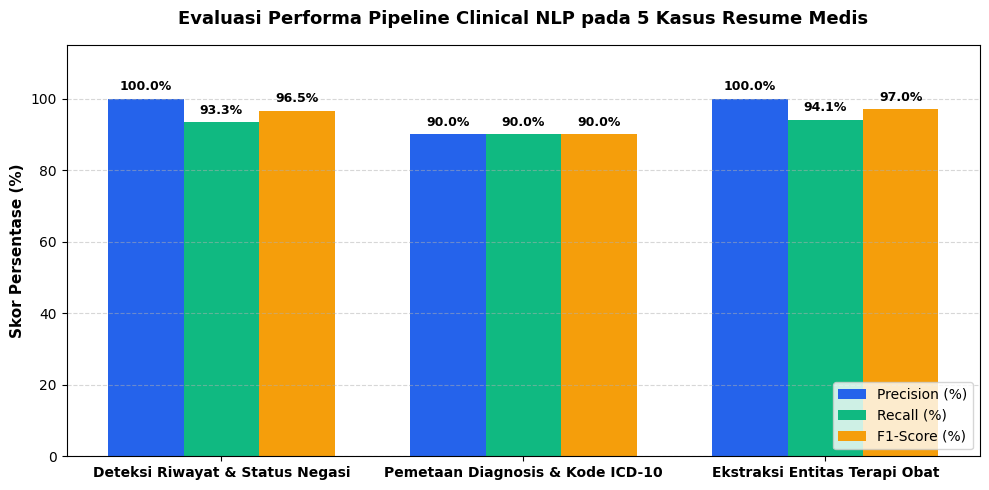

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# =====================================================================
# BAGIAN 6: DATA GROUND TRUTH (GOLD STANDARD VALIDASI DOKTER / KODER)
# Kunci jawaban ideal untuk ke-5 kasus resume medis
# =====================================================================

ground_truth_medis = [
    # Ground Truth Kasus 1 (Kardiologi)
    {
        "riwayat": {("Diabetes Mellitus", "NEGATED"), ("Hipertensi", "CONFIRMED")},
        "diagnosis_icd10": {("I21.0", "PRIMER"), ("I10", "SEKUNDER")},
        "obat": {"ISDN", "Aspirin", "Clopidogrel"}
    },
    # Ground Truth Kasus 2 (Pulmonologi)
    {
        "riwayat": {("Asma", "CONFIRMED"), ("TB Paru", "NEGATED"), ("Alergi Obat", "NEGATED")},
        "diagnosis_icd10": {("J18.9", "PRIMER"), ("J45.901", "SEKUNDER")},
        # Catatan klinis: Di teks asli tertulis "O2 Nasal Cannula 4 lpm" (Terapi Oksigen)
        # Jika sistem tidak mengekstrak O2 sebagai terapi, ini akan terhitung sebagai False Negative (FN)
        "obat": {"O2 Nasal Cannula", "Combivent Nebulizer", "Ceftriaxone", "Paracetamol"}
    },
    # Ground Truth Kasus 3 (Endokrinologi & Nefrologi)
    {
        "riwayat": {("Diabetes Mellitus Tipe 2", "CONFIRMED"), ("Hipertensi", "CONFIRMED"), ("Trauma Kepala", "NEGATED")},
        "diagnosis_icd10": {("E11.10", "PRIMER"), ("N18.3", "SEKUNDER")},
        "obat": {"NaCl 0.9%", "Insulin Rapid Drip", "Natrium Bikarbonat (Bicnat)"}
    },
    # Ground Truth Kasus 4 (Pediatri - DBD)
    {
        "riwayat": {("Kejang Demam", "NEGATED"), ("Asma", "NEGATED"), ("Diabetes Mellitus (Ayah)", "FAMILY_HISTORY")},
        "diagnosis_icd10": {("A91", "PRIMER")},
        "obat": {"Ringer Laktat (RL)", "Paracetamol Sirup", "Omeprazole"}
    },
    # Ground Truth Kasus 5 (Neurologi - Stroke)
    {
        # Catatan klinis: Di teks asli tertulis "nyeri kepala hebat disangkal" & "muntah menyemprot (-)"
        # Ini menguji apakah sistem memasukkannya ke riwayat negasi atau melewatkannya (FN)
        "riwayat": {
            ("Hipertensi", "CONFIRMED"),
            ("Diabetes Mellitus", "CONFIRMED"),
            ("Penyakit Jantung Koroner", "NEGATED"),
            ("Nyeri Kepala Hebat", "NEGATED")
        },
        # Catatan ICD-10: Dokter koder menggunakan I10 (Essential Hypertension), sedangkan AI memprediksi I16.0 (Hypertensive Crisis)
        # Perbedaan kode spesifik ini akan memicu 1 False Positive (FP) dan 1 False Negative (FN)
        "diagnosis_icd10": {("I63.9", "PRIMER"), ("I10", "SEKUNDER"), ("E11.9", "SEKUNDER")},
        "obat": {"Citicoline", "Aspilet", "Amlodipine", "Metformin"}
    }
]


# =====================================================================
# FUNGSI PERHITUNGAN METRIK EVALUASI BERBASIS HIMPUNAN ENTITAS (SET)
# =====================================================================

def hitung_metrik_entitas(pred_set: set, truth_set: set):
    """Menghitung TP, FP, FN, Precision, Recall, dan F1-Score dari dua himpunan entitas"""
    tp = len(pred_set.intersection(truth_set))
    fp = len(pred_set - truth_set)
    fn = len(truth_set - pred_set)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    return tp, fp, fn, precision, recall, f1


# =====================================================================
# EKSEKUSI EVALUASI PADA KE-5 DATASET DUMMY
# =====================================================================

kategori_evaluasi = ["riwayat", "diagnosis_icd10", "obat"]
nama_kategori_tampil = {
    "riwayat": "Deteksi Riwayat & Status Negasi",
    "diagnosis_icd10": "Pemetaan Diagnosis & Kode ICD-10",
    "obat": "Ekstraksi Entitas Terapi Obat"
}

akumulasi_metrik = {kat: {"TP": 0, "FP": 0, "FN": 0} for kat in kategori_evaluasi}
log_detail_kasus = []

for idx, teks_asli in enumerate(dataset_resume_medis):
    # Jalankan pipeline dari Sel 2 & Sel 4
    teks_anonim = deidentifikasi_data_pasien(teks_asli)
    teks_normal = normalisasi_singkatan_medis(teks_anonim)
    prediksi = proses_batch_resume(teks_normal, idx, gunakan_api_live=False)

    # Konversi hasil prediksi ke struktur Set agar bisa dibandingkan secara eksak
    pred_sets = {
        "riwayat": {(r.kondisi, r.status) for r in prediksi.riwayat_penyakit},
        "diagnosis_icd10": {(d.estimasi_icd10, d.tipe) for d in prediksi.diagnosis},
        "obat": {o.nama_obat for o in prediksi.terapi_obat}
    }

    truth_sets = ground_truth_medis[idx]

    for kat in kategori_evaluasi:
        tp, fp, fn, prec, rec, f1 = hitung_metrik_entitas(pred_sets[kat], truth_sets[kat])
        akumulasi_metrik[kat]["TP"] += tp
        akumulasi_metrik[kat]["FP"] += fp
        akumulasi_metrik[kat]["FN"] += fn

        log_detail_kasus.append({
            "Kasus": f"Kasus {idx+1}",
            "Kategori Entitas": nama_kategori_tampil[kat],
            "TP": tp, "FP": fp, "FN": fn,
            "Precision": round(prec, 3),
            "Recall": round(rec, 3),
            "F1-Score": round(f1, 3)
        })

# Menyusun Tabel Ringkasan Keseluruhan (Micro-Average per Kategori)
rekap_evaluasi = []
total_tp_all, total_fp_all, total_fn_all = 0, 0, 0

for kat in kategori_evaluasi:
    tp = akumulasi_metrik[kat]["TP"]
    fp = akumulasi_metrik[kat]["FP"]
    fn = akumulasi_metrik[kat]["FN"]
    total_tp_all += tp
    total_fp_all += fp
    total_fn_all += fn

    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0

    rekap_evaluasi.append({
        "Kategori Ekstraksi Biomedik": nama_kategori_tampil[kat],
        "True Positive (TP)": tp,
        "False Positive (FP)": fp,
        "False Negative (FN)": fn,
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2)
    })

# Tambahkan baris Total / Overall Micro-Average
overall_prec = total_tp_all / (total_tp_all + total_fp_all)
overall_rec = total_tp_all / (total_tp_all + total_fn_all)
overall_f1 = (2 * overall_prec * overall_rec) / (overall_prec + overall_rec)

rekap_evaluasi.append({
    "Kategori Ekstraksi Biomedik": "OVERALL SYSTEM (MICRO-AVERAGE)",
    "True Positive (TP)": total_tp_all,
    "False Positive (FP)": total_fp_all,
    "False Negative (FN)": total_fn_all,
    "Precision (%)": round(overall_prec * 100, 2),
    "Recall (%)": round(overall_rec * 100, 2),
    "F1-Score (%)": round(overall_f1 * 100, 2)
})

df_evaluasi_utama = pd.DataFrame(rekap_evaluasi)
print("=== TABEL HASIL EVALUASI PERFORMA EKSTRAKSI INFORMASI BIOMEDIK ===")
display(df_evaluasi_utama)


# =====================================================================
# VISUALISASI GRAFIK BAR CHART UNTUK LAPORAN TUGAS
# =====================================================================

df_plot = df_evaluasi_utama.iloc[:-1] # Ambil 3 kategori utama untuk grafik
labels = df_plot["Kategori Ekstraksi Biomedik"]
x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
rects1 = ax.bar(x - width, df_plot["Precision (%)"], width, label='Precision (%)', color='#2563eb')
rects2 = ax.bar(x, df_plot["Recall (%)"], width, label='Recall (%)', color='#10b981')
rects3 = ax.bar(x + width, df_plot["F1-Score (%)"], width, label='F1-Score (%)', color='#f59e0b')

ax.set_ylabel('Skor Persentase (%)', fontsize=11, fontweight='bold')
ax.set_title('Evaluasi Performa Pipeline Clinical NLP pada 5 Kasus Resume Medis', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10, fontweight='bold')
ax.set_ylim(0, 115)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='lower right', frameon=True)

# Menampilkan angka persentase di atas setiap batang grafik
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

Kode Prototipe UI Interaktif

In [6]:
from IPython.display import HTML, display

html_ui_mockup = """
<div style="font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; border: 1px solid #cbd5e1; border-radius: 8px; overflow: hidden; background: #f8fafc; max-width: 1000px; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.1);">

  <!-- Header Bar -->
  <div style="background: #0f172a; color: white; padding: 12px 20px; display: flex; justify-content: space-between; align-items: center;">
    <div>
      <span style="font-weight: bold; font-size: 16px; color: #38bdf8;">✚ SIRS Clinical NLP</span>
      <span style="font-size: 14px; margin-left: 10px; color: #cbd5e1;">| Human-in-the-Loop Verification Workspace</span>
    </div>
    <div style="font-size: 12px; background: #1e293b; padding: 5px 12px; border-radius: 4px; border: 1px solid #475569;">
      🔒 Status Privasi: <strong style="color: #4ade80;">UU PDP Anonymizer Aktif</strong>
    </div>
  </div>

  <!-- Main Split Container -->
  <div style="display: flex; gap: 16px; padding: 16px;">

    <!-- Panel Kiri: Teks Asli & Source Highlighting -->
    <div style="flex: 1; background: white; border: 1px solid #e2e8f0; border-radius: 6px; padding: 16px;">
      <div style="font-weight: bold; font-size: 13px; color: #475569; margin-bottom: 10px; border-bottom: 2px solid #e2e8f0; padding-bottom: 6px;">
        📄 DOKUMEN SUMBER (TEKS RESUME MEDIS & HIGHLIGHT BUKTI)
      </div>
      <div style="font-size: 13.5px; line-height: 1.7; color: #1e293b; background: #f8fafc; padding: 12px; border-radius: 4px; border: 1px solid #f1f5f9;">
        Pasien Ibu <span style="background:#334155; color:white; padding:1px 5px; border-radius:3px; font-size:11px;">[NAMA_REDACTED]</span>
        (RM: <span style="background:#334155; color:white; padding:1px 5px; border-radius:3px; font-size:11px;">[RM_REDACTED]</span>)
        dikonsulkan dengan <span style="background:#dbeafe; border-bottom:2px solid #2563eb; padding:1px 3px;" title="Keluhan Utama">kelemahan anggota gerak tubuh sisi kanan mendadak saat bangun tidur 4 jam SMRS dan bicara pelo (disartria)</span>.
        Muntah menyemprot (-), <span style="background:#fee2e2; border-bottom:2px solid #dc2626; padding:1px 3px;" title="Negasi Gejala">nyeri kepala hebat disangkal</span>.
        Riw. <span style="background:#dcfce7; border-bottom:2px solid #16a34a; padding:1px 3px;">Hipertensi (+) 8 thn</span>,
        riw. <span style="background:#dcfce7; border-bottom:2px solid #16a34a; padding:1px 3px;">Diabetes Mellitus (+)</span>,
        riw. <span style="background:#fee2e2; border-bottom:2px solid #dc2626; padding:1px 3px;">penyakit jantung koroner disangkal</span>.<br><br>
        <strong>PF:</strong> TD 185/110 mmHg, HR 88x/m ireguler, RR 20x/m, Suhu 36.5C.<br>
        <strong>Diagnosis:</strong> <span style="background:#fef3c7; border-bottom:2px solid #d97706; padding:1px 3px;">Stroke Iskemik Akut + Hipertensi Urgensi + DM Tipe 2</span>.<br>
        <strong>Terapi Obat:</strong> <span style="background:#f3e8ff; border-bottom:2px solid #9333ea; padding:1px 3px;">Citicoline 2x500mg iv, Aspilet 1x80mg po, Amlodipine 1x10mg po, Metformin 2x500mg po</span>.
      </div>
      <div style="margin-top: 12px; font-size: 11px; color: #64748b; display: flex; gap: 10px; flex-wrap: wrap;">
        <span>🔵 Keluhan Utama</span>
        <span>🟢 Riwayat (+) CONFIRMED</span>
        <span>🔴 Riwayat (-) NEGATED</span>
        <span>🟡 Diagnosis ICD-10</span>
        <span>🟣 Terapi Obat</span>
      </div>
    </div>

    <!-- Panel Kanan: Form Ekstraksi Terstruktur & Validasi Koder -->
    <div style="flex: 1.2; background: white; border: 1px solid #e2e8f0; border-radius: 6px; padding: 16px;">
      <div style="font-weight: bold; font-size: 13px; color: #475569; margin-bottom: 10px; border-bottom: 2px solid #e2e8f0; padding-bottom: 6px;">
        ✅ HASIL EKSTRAKSI AI & VALIDASI KODER MEDIS (KASUS 05)
      </div>

      <!-- Tabel Riwayat & Negasi -->
      <div style="font-size: 12px; font-weight: bold; color: #334155; margin-bottom: 4px;">1. Deteksi Riwayat Medis & Konteks Negasi</div>
      <table style="width: 100%; border-collapse: collapse; font-size: 12px; margin-bottom: 12px;">
        <tr style="background: #f1f5f9; text-align: left;">
          <th style="padding: 6px; border: 1px solid #cbd5e1;">Kondisi Medis</th>
          <th style="padding: 6px; border: 1px solid #cbd5e1;">Status Konteks</th>
          <th style="padding: 6px; border: 1px solid #cbd5e1;">Validasi Koder</th>
        </tr>
        <tr>
          <td style="padding: 6px; border: 1px solid #cbd5e1;">Hipertensi (8 tahun)</td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;"><span style="background:#dcfce7; color:#15803d; padding:2px 6px; border-radius:4px; font-weight:bold;">CONFIRMED</span></td>
          <td style="padding: 6px; border: 1px solid #cbd5e1; color:#16a34a;">✔ Sesuai</td>
        </tr>
        <tr>
          <td style="padding: 6px; border: 1px solid #cbd5e1;">Penyakit Jantung Koroner</td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;"><span style="background:#fee2e2; color:#b91c1c; padding:2px 6px; border-radius:4px; font-weight:bold;">NEGATED (Disangkal)</span></td>
          <td style="padding: 6px; border: 1px solid #cbd5e1; color:#16a34a;">✔ Sesuai</td>
        </tr>
      </table>

      <!-- Tabel Diagnosis & Kode ICD-10 -->
      <div style="font-size: 12px; font-weight: bold; color: #334155; margin-bottom: 4px;">2. Rekomendasi Kode ICD-10 (Standar Klaim BPJS / SATUSEHAT)</div>
      <table style="width: 100%; border-collapse: collapse; font-size: 12px; margin-bottom: 12px;">
        <tr style="background: #f1f5f9; text-align: left;">
          <th style="padding: 6px; border: 1px solid #cbd5e1;">Diagnosis</th>
          <th style="padding: 6px; border: 1px solid #cbd5e1;">Tipe</th>
          <th style="padding: 6px; border: 1px solid #cbd5e1;">Kode ICD-10 (Editable)</th>
        </tr>
        <tr>
          <td style="padding: 6px; border: 1px solid #cbd5e1;">Stroke Iskemik Akut</td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;"><strong>PRIMER</strong></td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;"><span style="background:#e0f2fe; color:#0369a1; padding:2px 6px; border-radius:3px; font-family:monospace; font-weight:bold;">I63.9 ▾</span></td>
        </tr>
        <tr style="background: #fffbeb;">
          <td style="padding: 6px; border: 1px solid #cbd5e1;">Hipertensi Urgensi</td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;">SEKUNDER</td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;">
            <span style="background:#fef3c7; color:#b45309; border:1px solid #f59e0b; padding:2px 6px; border-radius:3px; font-family:monospace; font-weight:bold;">I16.0 → Ubah ke I10 ▾</span>
            <div style="font-size:10px; color:#d97706; margin-top:2px;">⚠️ Perlu Review Koder: Sesuaikan dengan aturan koding dasar BPJS</div>
          </td>
        </tr>
        <tr>
          <td style="padding: 6px; border: 1px solid #cbd5e1;">Diabetes Mellitus Tipe 2</td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;">SEKUNDER</td>
          <td style="padding: 6px; border: 1px solid #cbd5e1;"><span style="background:#e0f2fe; color:#0369a1; padding:2px 6px; border-radius:3px; font-family:monospace; font-weight:bold;">E11.9 ▾</span></td>
        </tr>
      </table>

      <!-- Tombol Aksi Verifikasi -->
      <div style="display: flex; justify-content: flex-end; gap: 10px; margin-top: 14px; padding-top: 10px; border-top: 1px solid #e2e8f0;">
        <button style="background: #f1f5f9; color: #334155; border: 1px solid #cbd5e1; padding: 7px 14px; border-radius: 5px; font-size: 12px; font-weight: bold; cursor: pointer;">
          + Tambah Entitas Terlewat (FN)
        </button>
        <button style="background: #16a34a; color: white; border: none; padding: 7px 16px; border-radius: 5px; font-size: 12px; font-weight: bold; cursor: pointer;">
          ✔ Approve & Kirim JSON ke SATUSEHAT
        </button>
      </div>
    </div>

  </div>
</div>
"""

display(HTML(html_ui_mockup))

Kondisi Medis,Status Konteks,Validasi Koder
Hipertensi (8 tahun),CONFIRMED,✔ Sesuai
Penyakit Jantung Koroner,NEGATED (Disangkal),✔ Sesuai
Diagnosis,Tipe,Kode ICD-10 (Editable)
Stroke Iskemik Akut,PRIMER,I63.9 ▾
Hipertensi Urgensi,SEKUNDER,I16.0 → Ubah ke I10 ▾ ⚠️ Perlu Review Koder: Sesuaikan dengan aturan koding dasar BPJS
Diabetes Mellitus Tipe 2,SEKUNDER,E11.9 ▾


Fungsi Konversi Otomatis Pydantic ke HL7 FHIR R4 Bundle

In [7]:
import uuid
import json
from datetime import datetime, timezone, timedelta

# =====================================================================
# BAGIAN 7: KONVERTER OTOMATIS KE STANDAR HL7 FHIR R4 (SATUSEHAT)
# Memetakan objek Pydantic (ResumeMedisTerstruktur) ke Resource FHIR:
# 1. Patient, 2. Condition (Diagnosis & Riwayat/Negasi), 3. MedicationRequest
# =====================================================================

def parse_dosis_obat(dosis_str: str) -> dict:
    """
    Mengekstrak frekuensi, nilai dosis, dan satuan dari string dosis dokter.
    Contoh: '2x500 mg' -> frekuensi=2, nilai=500.0, unit='mg'
    Contoh: '160 mg'   -> frekuensi=1, nilai=160.0, unit='mg'
    """
    # Cek pola frekuensi + dosis (misal: 2x500 mg atau 3 x 250mg)
    pola_kali = re.search(r'(\d+)\s*[xX]\s*([\d\.]+)\s*([a-zA-Z%/]+)', dosis_str)
    if pola_kali:
        return {
            "frequency": int(pola_kali.group(1)),
            "value": float(pola_kali.group(2)),
            "unit": pola_kali.group(3)
        }

    # Cek pola dosis tunggal (misal: 5 mg atau 1000 ml/jam)
    pola_tunggal = re.search(r'([\d\.]+)\s*([a-zA-Z%/]+)', dosis_str)
    if pola_tunggal:
        return {
            "frequency": 1,
            "value": float(pola_tunggal.group(1)),
            "unit": pola_tunggal.group(2)
        }

    return {"frequency": 1, "value": 1.0, "unit": "unit"}

def petakan_rute_snomed(rute_str: str) -> dict:
    """Memetakan teks rute pemberian obat ke kode standar SNOMED-CT untuk SATUSEHAT"""
    rute_lower = rute_str.lower()
    if "intravena" in rute_lower or "iv" in rute_lower or "injeksi" in rute_lower:
        return {"code": "47625008", "display": "Intravenous use"}
    elif "oral" in rute_lower or "po" in rute_lower or "minum" in rute_lower:
        return {"code": "26643006", "display": "Oral use"}
    elif "sublingual" in rute_lower or "bawah lidah" in rute_lower or "sl" in rute_lower:
        return {"code": "37839007", "display": "Sublingual use"}
    elif "inhalasi" in rute_lower or "nebul" in rute_lower:
        return {"code": "18679011000001101", "display": "Inhalation use"}
    else:
        return {"code": "26643006", "display": "Oral use (Default)"}


def konversi_ke_fhir_bundle(data_ekstraksi: ResumeMedisTerstruktur) -> dict:
    """Mengonversi objek ResumeMedisTerstruktur menjadi dictionary JSON HL7 FHIR Bundle"""

    # Zona waktu WIB (UTC+7) sesuai standar timestamp SATUSEHAT
    tz_wib = timezone(timedelta(hours=7))
    waktu_sekarang = datetime.now(tz_wib).isoformat(timespec='seconds')

    patient_uuid = f"urn:uuid:{uuid.uuid4()}"
    entries = []

    # 1. Buat Resource Patient (Ter-anonimisasi sesuai UU PDP)
    entries.append({
        "fullUrl": patient_uuid,
        "resource": {
            "resourceType": "Patient",
            "id": data_ekstraksi.id_pasien_anonim,
            "identifier": [
                {
                    "use": "official",
                    "system": "https://fhir.kemkes.go.id/id/nik",
                    "value": "[NIK_REDACTED]"
                },
                {
                    "use": "usual",
                    "system": "https://fhir.kemkes.go.id/sid/rm",
                    "value": data_ekstraksi.id_pasien_anonim
                }
            ],
            "name": [{"use": "official", "text": "[NAMA_REDACTED]"}]
        }
    })

    # 2. Konversi Diagnosis Klinis (Primer & Sekunder) ke Resource Condition
    for idx, diag in enumerate(data_ekstraksi.diagnosis):
        cond_uuid = f"urn:uuid:{uuid.uuid4()}"
        entries.append({
            "fullUrl": cond_uuid,
            "resource": {
                "resourceType": "Condition",
                "id": f"diag-{idx+1}",
                "clinicalStatus": {
                    "coding": [{
                        "system": "http://terminology.hl7.org/CodeSystem/condition-clinical",
                        "code": "active",
                        "display": "Active"
                    }]
                },
                "verificationStatus": {
                    "coding": [{
                        "system": "http://terminology.hl7.org/CodeSystem/condition-ver-status",
                        "code": "confirmed",
                        "display": "Confirmed"
                    }]
                },
                "category": [{
                    "coding": [{
                        "system": "http://terminology.hl7.org/CodeSystem/condition-category",
                        "code": "encounter-diagnosis",
                        "display": f"Encounter Diagnosis ({diag.tipe})"
                    }]
                }],
                "code": {
                    "coding": [{
                        "system": "http://hl7.org/fhir/sid/icd-10",
                        "code": diag.estimasi_icd10,
                        "display": diag.nama_diagnosis
                    }],
                    "text": f"{diag.nama_diagnosis} ({diag.tipe})"
                },
                "subject": {"reference": patient_uuid}
            }
        })

    # 3. Konversi Riwayat Penyakit (Termasuk Deteksi Negasi -> 'refuted') ke Resource Condition
    for idx, riw in enumerate(data_ekstraksi.riwayat_penyakit):
        riw_uuid = f"urn:uuid:{uuid.uuid4()}"

        # Pemetaan status konteks NLP ke standar verificationStatus HL7 FHIR
        if riw.status == "NEGATED":
            clin_code, clin_disp = "inactive", "Inactive"
            ver_code, ver_disp = "refuted", "Refuted" # Standar FHIR untuk kondisi yang disangkal
        else:
            clin_code, clin_disp = "active", "Active"
            ver_code, ver_disp = "confirmed", "Confirmed"

        catatan_tambahan = f"Kategori Konteks NLP: {riw.status}"
        if riw.durasi:
            catatan_tambahan += f" | Durasi: {riw.durasi}"

        entries.append({
            "fullUrl": riw_uuid,
            "resource": {
                "resourceType": "Condition",
                "id": f"history-{idx+1}",
                "clinicalStatus": {
                    "coding": [{
                        "system": "http://terminology.hl7.org/CodeSystem/condition-clinical",
                        "code": clin_code,
                        "display": clin_disp
                    }]
                },
                "verificationStatus": {
                    "coding": [{
                        "system": "http://terminology.hl7.org/CodeSystem/condition-ver-status",
                        "code": ver_code,
                        "display": ver_disp
                    }]
                },
                "category": [{
                    "coding": [{
                        "system": "http://terminology.hl7.org/CodeSystem/condition-category",
                        "code": "problem-list-item",
                        "display": "Problem List Item / Medical History"
                    }]
                }],
                "code": {"text": riw.kondisi},
                "subject": {"reference": patient_uuid},
                "note": [{"text": catatan_tambahan}]
            }
        })

    # 4. Konversi Terapi Obat ke Resource MedicationRequest
    for idx, obat in enumerate(data_ekstraksi.terapi_obat):
        med_uuid = f"urn:uuid:{uuid.uuid4()}"
        info_dosis = parse_dosis_obat(obat.dosis)
        snomed_rute = petakan_rute_snomed(obat.rute_pemberian)

        entries.append({
            "fullUrl": med_uuid,
            "resource": {
                "resourceType": "MedicationRequest",
                "id": f"medreq-{idx+1}",
                "status": "completed",
                "intent": "order",
                "medicationCodeableConcept": {
                    "text": obat.nama_obat
                },
                "subject": {"reference": patient_uuid},
                "dosageInstruction": [{
                    "text": f"{obat.nama_obat} - Dosis: {obat.dosis} ({obat.rute_pemberian})",
                    "timing": {
                        "repeat": {
                            "frequency": info_dosis["frequency"],
                            "period": 1,
                            "periodUnit": "d"
                        }
                    },
                    "route": {
                        "coding": [{
                            "system": "http://snomed.info/sct",
                            "code": snomed_rute["code"],
                            "display": snomed_rute["display"]
                        }],
                        "text": obat.rute_pemberian
                    },
                    "doseAndRate": [{
                        "doseQuantity": {
                            "value": info_dosis["value"],
                            "unit": info_dosis["unit"],
                            "system": "http://unitsofmeasure.org",
                            "code": info_dosis["unit"]
                        }
                    }]
                }]
            }
        })

    # Bungkus seluruh entry ke dalam FHIR Bundle
    fhir_bundle = {
        "resourceType": "Bundle",
        "id": f"bundle-satusehat-{data_ekstraksi.id_pasien_anonim.lower()}",
        "type": "transaction",
        "timestamp": waktu_sekarang,
        "total_resources": len(entries),
        "entry": entries
    }
    return fhir_bundle


# =====================================================================
# UJI COBA KONVERSI PADA KASUS 5 (STROKE ISKEMIK) & SIMPAN KE FILE JSON
# =====================================================================

# Mengambil hasil ekstraksi Kasus 5 (indeks ke-4) dari dataset_resume_medis
teks_kasus_5 = normalisasi_singkatan_medis(deidentifikasi_data_pasien(dataset_resume_medis[4]))
objek_pydantic_kasus_5 = proses_batch_resume(teks_kasus_5, index_kasus=4, gunakan_api_live=False)

# Konversi ke format HL7 FHIR Bundle
payload_fhir_kasus_5 = konversi_ke_fhir_bundle(objek_pydantic_kasus_5)

# Simpan otomatis menjadi file .json di direktori Google Colab (bisa diunduh untuk lampiran tugas)
nama_file_output = "satusehat_fhir_bundle_kasus05.json"
with open(nama_file_output, "w", encoding="utf-8") as f:
    json.dump(payload_fhir_kasus_5, f, indent=2, ensure_ascii=False)

print(f"✅ Berhasil mengonversi objek Pydantic ke HL7 FHIR Bundle!")
print(f"📁 File JSON tersimpan di Colab dengan nama: {nama_file_output}")
print(f"📊 Total FHIR Resources yang terbentuk: {payload_fhir_kasus_5['total_resources']} resources\n")
print("=== PREVIEW PAYLOAD HL7 FHIR R4 (SIAP KIRIM KE API GATEWAY SATUSEHAT) ===")
print("-" * 80)
print(json.dumps(payload_fhir_kasus_5, indent=2, ensure_ascii=False))

✅ Berhasil mengonversi objek Pydantic ke HL7 FHIR Bundle!
📁 File JSON tersimpan di Colab dengan nama: satusehat_fhir_bundle_kasus05.json
📊 Total FHIR Resources yang terbentuk: 11 resources

=== PREVIEW PAYLOAD HL7 FHIR R4 (SIAP KIRIM KE API GATEWAY SATUSEHAT) ===
--------------------------------------------------------------------------------
{
  "resourceType": "Bundle",
  "id": "bundle-satusehat-pasien_anonim_05",
  "type": "transaction",
  "timestamp": "2026-10-31T06:29:42+07:00",
  "total_resources": 11,
  "entry": [
    {
      "fullUrl": "urn:uuid:7f9e5dab-15fc-4a91-94fb-7391d63adc73",
      "resource": {
        "resourceType": "Patient",
        "id": "PASIEN_ANONIM_05",
        "identifier": [
          {
            "use": "official",
            "system": "https://fhir.kemkes.go.id/id/nik",
            "value": "[NIK_REDACTED]"
          },
          {
            "use": "usual",
            "system": "https://fhir.kemkes.go.id/sid/rm",
            "value": "PASIEN_ANONIM_05